## Treci domaci zadatak (Reinforcement learning)

In [21]:
import numpy as np
import random
import matplotlib.pyplot as plt

%matplotlib inline
np.set_printoptions(precision=4, suppress=True)

Okruzenje

In [22]:
ROWS = ['A', 'B']
COLS = [1, 2, 3, 4, 5]
ALL_STATES = [(r, c) for r in ROWS for c in COLS]

TERMINAL_REWARDS = {('B', 1): -1.0, ('B', 3): 1.0, ('B', 5): -1.0}
TERMINAL_STATES = set(TERMINAL_REWARDS.keys())
NONTERMINAL_STATES = [s for s in ALL_STATES if s not in TERMINAL_STATES]
STEP_REWARD = -0.04

ACTIONS = ['gore', 'dole', 'levo', 'desno']
ACTION_IDX = {a: i for i, a in enumerate(ACTIONS)}
DELTA = {'gore': (-1, 0), 'dole': (1, 0), 'levo': (0, -1), 'desno': (0, 1)}

print("Sva stanja:", ALL_STATES)
print("Terminalna stanja:", TERMINAL_STATES)
print("Neterminalna stanja:", NONTERMINAL_STATES)

Sva stanja: [('A', 1), ('A', 2), ('A', 3), ('A', 4), ('A', 5), ('B', 1), ('B', 2), ('B', 3), ('B', 4), ('B', 5)]
Terminalna stanja: {('B', 1), ('B', 3), ('B', 5)}
Neterminalna stanja: [('A', 1), ('A', 2), ('A', 3), ('A', 4), ('A', 5), ('B', 2), ('B', 4)]


In [23]:
def apply_action(state, action): 
    r, c = state
    ri = ROWS.index(r)
    dr, dc = DELTA[action]
    nri, nc = ri + dr, c + dc
    if 0 <= nri <= 1 and 1 <= nc <= 5:
        return (ROWS[nri], nc)
    return state


def transition_distribution(state, action): 
    # vraca raspodelu verovatnoca za svako moguce sledece stanje nakon akcije
    assert state not in TERMINAL_STATES
    probs = {}

    def add(ns, p):
        probs[ns] = probs.get(ns, 0.0) + p

    add(apply_action(state, action), 0.6)
    for a in ACTIONS:
        if a != action:
            add(apply_action(state, a), 0.1)
    add(state, 0.1)  

    return probs


def reward_for_transition(next_state):
    return TERMINAL_REWARDS.get(next_state, STEP_REWARD)

Simulator

In [24]:
class GridEnv:

    def __init__(self, rng=None):
        self.rng = rng if rng is not None else random.Random()
        self.state = None
        self.reset()

    def reset(self):
        self.state = self.rng.choice(NONTERMINAL_STATES)
        return self.state

    def step(self, action):
        if self.state in TERMINAL_STATES:
            raise RuntimeError("Epizoda je zavrsena, pozvati reset().")
        dist = transition_distribution(self.state, action)
        states, probs = zip(*dist.items())
        next_state = self.rng.choices(states, weights=probs, k=1)[0]
        reward = reward_for_transition(next_state)
        self.state = next_state
        done = next_state in TERMINAL_STATES
        return reward, next_state, done

    def get_transition_model(self, state, action):
        # koristi ga saamo iteracija Q-vrednosti
        return transition_distribution(state, action)

In [25]:
# test simulatora

rng_demo = random.Random(42)
env_demo = GridEnv(rng=rng_demo)

for ep in range(5):
    s = env_demo.reset()
    done = False
    steps = 0
    while not done and steps < 200:
        a = rng_demo.choice(ACTIONS)
        r, s, done = env_demo.step(a)
        steps += 1
    print(f"Epizoda {ep}: {steps:3d} koraka, zavrsena u {s}, poslednja nagrada {r:+.2f}")

Epizoda 0:   2 koraka, zavrsena u ('B', 1), poslednja nagrada -1.00
Epizoda 1:   7 koraka, zavrsena u ('B', 3), poslednja nagrada +1.00
Epizoda 2:   8 koraka, zavrsena u ('B', 3), poslednja nagrada +1.00
Epizoda 3:  12 koraka, zavrsena u ('B', 1), poslednja nagrada -1.00
Epizoda 4:   2 koraka, zavrsena u ('B', 3), poslednja nagrada +1.00


Iteracija Q-vrednosti


In [26]:
def q_value_iteration(gamma=0.9, n_iter=1000, tol=1e-10, verbose=False):
    #koristimo poznat model okruženja (P, R)

    Q = {(s, a): 0.0 for s in NONTERMINAL_STATES for a in ACTIONS}

    def max_Q(state):
        # V(s) = max_a Q(s,a); za terminalno stanje nema dalje
        if state in TERMINAL_STATES:
            return 0.0
        return max(Q[(state, a)] for a in ACTIONS)

    for t in range(n_iter):
        Q_new = {}
        max_diff = 0.0
        for s in NONTERMINAL_STATES:
            for a in ACTIONS:
                dist = transition_distribution(s, a)
                expected_reward = sum(p * reward_for_transition(ns) for ns, p in dist.items())
                expected_future = sum(p * max_Q(ns) for ns, p in dist.items())
                q_new = expected_reward + gamma * expected_future
                Q_new[(s, a)] = q_new
                max_diff = max(max_diff, abs(q_new - Q[(s, a)]))
        Q = Q_new
        if max_diff < tol:
            if verbose:
                print(f"Konvergiralo posle {t+1} iteracija.")
            break
    return Q


GAMMA = 0.9
Q_star = q_value_iteration(gamma=GAMMA, verbose=True)

Konvergiralo posle 45 iteracija.


In [27]:
def print_policy_table(Q, states=NONTERMINAL_STATES, actions=ACTIONS):
    for s in states:
        row = "  ".join(f"{a}:{Q[(s,a)]:+.4f}" for a in actions)
        best_a = max(actions, key=lambda a: Q[(s, a)])
        print(f"{s}:  {row}   ->  najbolja akcija: {best_a}")

print("Q*(s,a) za svako neterminalno stanje (gamma = 0.9):\n")
print_policy_table(Q_star)

V_star = {s: max(Q_star[(s, a)] for a in ACTIONS) for s in NONTERMINAL_STATES}
print("\nV*(s) = max_a Q*(s,a):")
for s in NONTERMINAL_STATES:
    print(f"  {s}: {V_star[s]:.4f}")

Q*(s,a) za svako neterminalno stanje (gamma = 0.9):

('A', 1):  gore:+0.1098  dole:-0.4895  levo:+0.1098  desno:+0.2651   ->  najbolja akcija: desno
('A', 2):  gore:+0.5040  dole:+0.5274  levo:+0.3487  desno:+0.6102   ->  najbolja akcija: desno
('A', 3):  gore:+0.7069  dole:+0.8461  levo:+0.6007  desno:+0.6007   ->  najbolja akcija: dole
('A', 4):  gore:+0.5040  dole:+0.5274  levo:+0.6102  desno:+0.3487   ->  najbolja akcija: levo
('A', 5):  gore:+0.1098  dole:-0.4895  levo:+0.2651  desno:+0.1098   ->  najbolja akcija: levo
('B', 2):  gore:+0.4167  dole:+0.4400  levo:-0.3379  desno:+0.6621   ->  najbolja akcija: desno
('B', 4):  gore:+0.4167  dole:+0.4400  levo:+0.6621  desno:-0.3379   ->  najbolja akcija: levo

V*(s) = max_a Q*(s,a):
  ('A', 1): 0.2651
  ('A', 2): 0.6102
  ('A', 3): 0.8461
  ('A', 4): 0.6102
  ('A', 5): 0.2651
  ('B', 2): 0.6621
  ('B', 4): 0.6621


Q-učenje


Q(s_t, a_t) <- Q(s_t, a_t) + α * [ r_t + γ * max_a' Q(s_t+1, a') - Q(s_t, a_t) ]

gde je izraz u zagradi TD-greska razlika izmedju boljeg cilja i trenutne procene 

In [28]:
def epsilon_greedy_action(Q, state, eps, rng):
    if rng.random() < eps:
        return rng.choice(ACTIONS)
    qs = [Q[(state, a)] for a in ACTIONS]
    best = max(qs)
    best_actions = [a for a, q in zip(ACTIONS, qs) if q == best]  
    return rng.choice(best_actions)

In [29]:
def q_learning(n_episodes, gamma=0.9, eps=0.1, alpha_mode='decay',
               alpha_const=0.1, seed=0, track_every=50):
    rng = random.Random(seed)
    env = GridEnv(rng=rng)
    Q = {(s, a): 0.0 for s in NONTERMINAL_STATES for a in ACTIONS}
    history = []

    for ep in range(1, n_episodes + 1):
        alpha = np.log(ep + 1) / (ep + 1) if alpha_mode == 'decay' else alpha_const

        s = env.reset()
        done = False
        while not done:
            a = epsilon_greedy_action(Q, s, eps, rng)
            r, s_next, done = env.step(a)
            target = r if done else r + gamma * max(Q[(s_next, a2)] for a2 in ACTIONS)
            Q[(s, a)] += alpha * (target - Q[(s, a)])
            s = s_next

        if ep % track_every == 0 or ep == 1:
            V = {st: max(Q[(st, a)] for a in ACTIONS) for st in NONTERMINAL_STATES}
            history.append((ep, V))

    return Q, history

In [30]:
N_EPISODES = 20000

Q_learned, history = q_learning(n_episodes=N_EPISODES, gamma=GAMMA, eps=0.1,
                                 alpha_mode='decay', seed=1)

print("Naucene Q-vrednosti vs Q* (referenca iz iteracije Q-vrednosti):\n")
n_mismatch = 0
for s in NONTERMINAL_STATES:
    best_learned = max(ACTIONS, key=lambda a: Q_learned[(s, a)])
    best_ref = max(ACTIONS, key=lambda a: Q_star[(s, a)])
    match = "OK" if best_learned == best_ref else "RAZLIKA"
    if match == "RAZLIKA":
        n_mismatch += 1
    print(f"{s}: naucena najbolja akcija = {best_learned:6s} | referentna = {best_ref:6s}  [{match}]")

print(f"\nBroj stanja sa razlikom u optimalnoj akciji: {n_mismatch}/{len(NONTERMINAL_STATES)}")

max_err = max(abs(max(Q_learned[(s,a)] for a in ACTIONS) - V_star[s]) for s in NONTERMINAL_STATES)
print(f"Max |V_learned(s) - V*(s)| = {max_err:.4f}")

Naucene Q-vrednosti vs Q* (referenca iz iteracije Q-vrednosti):

('A', 1): naucena najbolja akcija = desno  | referentna = desno   [OK]
('A', 2): naucena najbolja akcija = desno  | referentna = desno   [OK]
('A', 3): naucena najbolja akcija = dole   | referentna = dole    [OK]
('A', 4): naucena najbolja akcija = levo   | referentna = levo    [OK]
('A', 5): naucena najbolja akcija = levo   | referentna = levo    [OK]
('B', 2): naucena najbolja akcija = desno  | referentna = desno   [OK]
('B', 4): naucena najbolja akcija = levo   | referentna = levo    [OK]

Broj stanja sa razlikom u optimalnoj akciji: 0/7
Max |V_learned(s) - V*(s)| = 0.0107


 Pracenje konvergencije: V_t(s) vs V*(s)



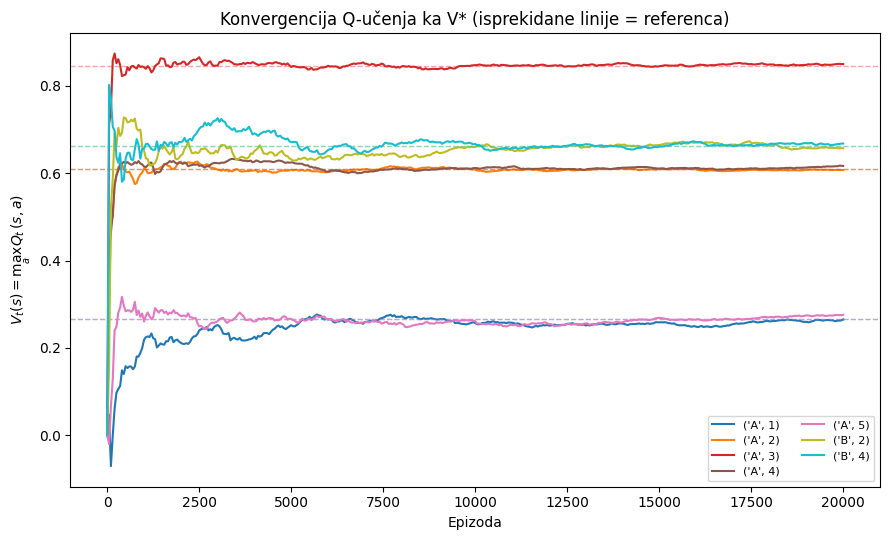

In [31]:
fig, ax = plt.subplots(figsize=(9, 5.5))
colors = plt.cm.tab10(np.linspace(0, 1, len(NONTERMINAL_STATES)))

for s, color in zip(NONTERMINAL_STATES, colors):
    eps_list = [h[0] for h in history]
    v_list = [h[1][s] for h in history]
    ax.plot(eps_list, v_list, label=f"{s}", color=color)
    ax.axhline(V_star[s], linestyle='--', color=color, alpha=0.4, linewidth=1)

ax.set_xlabel("Epizoda")
ax.set_ylabel(r"$V_t(s) = \max_a Q_t(s,a)$")
ax.set_title(r"Konvergencija Q-učenja ka V* (isprekidane linije = referenca)")
ax.legend(fontsize=8, ncol=2, loc='lower right')
plt.tight_layout()
plt.show()

 Opadajuća vs konstantna stopa učenja

Sada poredimo α_e = ln(e+1)/(e+1) (opada ka nuli) sa const stopom
α = 0.1, da vidimo razliku u konvergenciji 

In [32]:
Q_const, history_const = q_learning(n_episodes=N_EPISODES, gamma=GAMMA, eps=0.1,
                                     alpha_mode='const', alpha_const=0.1, seed=1)

err_decay = max(abs(max(Q_learned[(s,a)] for a in ACTIONS) - V_star[s]) for s in NONTERMINAL_STATES)
err_const = max(abs(max(Q_const[(s,a)] for a in ACTIONS) - V_star[s]) for s in NONTERMINAL_STATES)

print(f"Max |V - V*| posle {N_EPISODES} epizoda:")
print(f"  opadajuca stopa (alpha_e = ln(e+1)/(e+1)): {err_decay:.4f}")
print(f"  konstantna stopa (alpha = 0.1):            {err_const:.4f}")

Max |V - V*| posle 20000 epizoda:
  opadajuca stopa (alpha_e = ln(e+1)/(e+1)): 0.0107
  konstantna stopa (alpha = 0.1):            0.3276


Testiranje naučene politike



In [33]:
def greedy_policy_from_Q(Q):
    return {s: max(ACTIONS, key=lambda a: Q[(s, a)]) for s in NONTERMINAL_STATES}


def evaluate_policy(policy, n_episodes=10, seed=123, max_steps=500):
    """Vraća listu ukupnih (sirovih, nediskontovanih) nagrada, jedna po epizodi."""
    rng = random.Random(seed)
    env = GridEnv(rng=rng)
    totals = []
    for _ in range(n_episodes):
        s = env.reset()
        done = False
        total = 0.0
        steps = 0
        while not done and steps < max_steps:
            a = policy[s]
            r, s, done = env.step(a)
            total += r
            steps += 1
        totals.append(total)
    return totals


policy_09 = greedy_policy_from_Q(Q_learned)
rewards_09 = evaluate_policy(policy_09, n_episodes=10, seed=7)

print("Politika (gamma = 0.9):")
for s in NONTERMINAL_STATES:
    print(f"  {s}: {policy_09[s]}")

print(f"\nUkupne nagrade po epizodi: {[round(r,2) for r in rewards_09]}")
print(f"Prosecna ukupna nagrada (10 epizoda): {np.mean(rewards_09):.4f}")

Politika (gamma = 0.9):
  ('A', 1): desno
  ('A', 2): desno
  ('A', 3): dole
  ('A', 4): levo
  ('A', 5): levo
  ('B', 2): desno
  ('B', 4): levo

Ukupne nagrade po epizodi: [0.96, 1.0, 1.0, 0.92, 0.96, 1.0, 0.92, 0.84, 0.96, 0.84]
Prosecna ukupna nagrada (10 epizoda): 0.9400


In [34]:
# Ponavljanje za γ = 0.999


GAMMA_HIGH = 0.999
N_EPISODES_HIGH = 30000  # malo vise epizoda , vece gamma => sporija konvergencija

Q_learned_999, history_999 = q_learning(n_episodes=N_EPISODES_HIGH, gamma=GAMMA_HIGH,
                                         eps=0.1, alpha_mode='decay', seed=1)

# referenca za gamma=0.999 
Q_star_999 = q_value_iteration(gamma=GAMMA_HIGH)

policy_999 = greedy_policy_from_Q(Q_learned_999)
rewards_999 = evaluate_policy(policy_999, n_episodes=10, seed=7)

print("Politika (gamma = 0.999):")
for s in NONTERMINAL_STATES:
    ref_best = max(ACTIONS, key=lambda a: Q_star_999[(s, a)])
    flag = "OK" if policy_999[s] == ref_best else "  <- razlikuje se od referentne optimalne akcije"
    print(f"  {s}: {policy_999[s]:6s} (referentno optimalno: {ref_best:6s}) {flag}")

print(f"\nUkupne nagrade po epizodi: {[round(r,2) for r in rewards_999]}")
print(f"Prosecna ukupna nagrada (10 epizoda): {np.mean(rewards_999):.4f}")

print(f"\nPoredjenje: gamma=0.9 prosek = {np.mean(rewards_09):.4f}, gamma=0.999 prosek = {np.mean(rewards_999):.4f}")

Politika (gamma = 0.999):
  ('A', 1): desno  (referentno optimalno: desno ) OK
  ('A', 2): desno  (referentno optimalno: desno ) OK
  ('A', 3): dole   (referentno optimalno: dole  ) OK
  ('A', 4): levo   (referentno optimalno: levo  ) OK
  ('A', 5): levo   (referentno optimalno: levo  ) OK
  ('B', 2): gore   (referentno optimalno: desno )   <- razlikuje se od referentne optimalne akcije
  ('B', 4): levo   (referentno optimalno: levo  ) OK

Ukupne nagrade po epizodi: [0.96, 1.0, 1.0, 0.92, 0.96, 1.0, 0.92, 0.84, 0.96, 0.84]
Prosecna ukupna nagrada (10 epizoda): 0.9400

Poredjenje: gamma=0.9 prosek = 0.9400, gamma=0.999 prosek = 0.9400


 REINFORCE 




In [35]:
def softmax(x):
    x = x - np.max(x)  # numericka stabilnost
    e = np.exp(x)
    return e / e.sum()


class SoftmaxPolicy:
    #theta[s] je vektor od 4 logita (po jedan za svaku akciju u ACTIONS)

    def __init__(self):
        self.state_idx = {s: i for i, s in enumerate(NONTERMINAL_STATES)}
        self.theta = np.zeros((len(NONTERMINAL_STATES), len(ACTIONS)))

    def probs(self, state):
        return softmax(self.theta[self.state_idx[state]])

    def sample_action(self, state, rng):
        p = self.probs(state)
        idx = rng.choices(range(len(ACTIONS)), weights=p, k=1)[0]
        return ACTIONS[idx]

    def grad_log_pi(self, state, action):
        #d/d theta_{s,a'} log pi(a|s) = 1[a'==a] - pi(a'|s)
        grad = -self.probs(state)
        grad[ACTION_IDX[action]] += 1.0
        return grad

    def update(self, state, action, step):
        #step = alpha * G_t (skalar koji vec sadrzi stopu ucenja i povratak)
        si = self.state_idx[state]
        self.theta[si, :] += step * self.grad_log_pi(state, action)

In [36]:
def run_episode_reinforce(env, policy, rng, max_steps=300):
    s = env.reset()
    states, actions, rewards = [], [], []
    done = False
    steps = 0
    while not done and steps < max_steps:
        a = policy.sample_action(s, rng)
        r, s_next, done = env.step(a)
        states.append(s); actions.append(a); rewards.append(r)
        s = s_next
        steps += 1
    return states, actions, rewards


def discounted_returns(rewards, gamma):
    #G_t za svaki korak t, racunato unazad: G_t = r_t + gamma*G_{t+1}
    G = np.zeros(len(rewards))
    running = 0.0
    for t in reversed(range(len(rewards))):
        running = rewards[t] + gamma * running
        G[t] = running
    return G

In [37]:
def reinforce(n_episodes, gamma=0.9, alpha=0.05, seed=0, track_every=20):
    rng = random.Random(seed)
    env = GridEnv(rng=rng)
    policy = SoftmaxPolicy()
    episode_total_rewards = []   # sirova  ukupna nagrada po epizodi
    theta_history = []

    for ep in range(1, n_episodes + 1):
        states, actions, rewards = run_episode_reinforce(env, policy, rng)
        G = discounted_returns(rewards, gamma)
        for t in range(len(states)):
            policy.update(states[t], actions[t], alpha * G[t])
        episode_total_rewards.append(sum(rewards))
        if ep % track_every == 0 or ep == 1:
            theta_history.append((ep, policy.theta.copy()))

    return policy, episode_total_rewards, theta_history

In [38]:
N_EPISODES_REINFORCE = 8000

policy_rf, rewards_rf, theta_hist = reinforce(n_episodes=N_EPISODES_REINFORCE,
                                               gamma=GAMMA, alpha=0.05, seed=0)

print("Naucena politika (najverovatnija akcija po stanju):\n")
n_mismatch = 0
for s in NONTERMINAL_STATES:
    p = policy_rf.probs(s)
    best = ACTIONS[np.argmax(p)]
    best_ref = max(ACTIONS, key=lambda a: Q_star[(s, a)])
    flag = "OK" if best == best_ref else "RAZLIKA"
    if flag == "RAZLIKA":
        n_mismatch += 1
    probs_str = ", ".join(f"{a}:{pi:.3f}" for a, pi in zip(ACTIONS, p))
    print(f"{s}: najverovatnija = {best:6s} (ref. optimalna = {best_ref:6s}) [{flag}]   pi(.|s) = [{probs_str}]")

print(f"\nBroj stanja sa razlikom: {n_mismatch}/{len(NONTERMINAL_STATES)}")
print(f"\nProsecna ukupna nagrada, prvih 200 epizoda:    {np.mean(rewards_rf[:200]):.4f}")
print(f"Prosecna ukupna nagrada, poslednjih 200 epizoda: {np.mean(rewards_rf[-200:]):.4f}")

Naucena politika (najverovatnija akcija po stanju):

('A', 1): najverovatnija = desno  (ref. optimalna = desno ) [OK]   pi(.|s) = [gore:0.012, dole:0.003, levo:0.011, desno:0.974]
('A', 2): najverovatnija = desno  (ref. optimalna = desno ) [OK]   pi(.|s) = [gore:0.019, dole:0.069, levo:0.006, desno:0.906]
('A', 3): najverovatnija = dole   (ref. optimalna = dole  ) [OK]   pi(.|s) = [gore:0.004, dole:0.991, levo:0.003, desno:0.002]
('A', 4): najverovatnija = levo   (ref. optimalna = levo  ) [OK]   pi(.|s) = [gore:0.026, dole:0.081, levo:0.889, desno:0.005]
('A', 5): najverovatnija = levo   (ref. optimalna = levo  ) [OK]   pi(.|s) = [gore:0.014, dole:0.004, levo:0.966, desno:0.017]
('B', 2): najverovatnija = desno  (ref. optimalna = desno ) [OK]   pi(.|s) = [gore:0.006, dole:0.008, levo:0.002, desno:0.984]
('B', 4): najverovatnija = levo   (ref. optimalna = levo  ) [OK]   pi(.|s) = [gore:0.007, dole:0.010, levo:0.981, desno:0.003]

Broj stanja sa razlikom: 0/7

Prosecna ukupna nagrada, pr

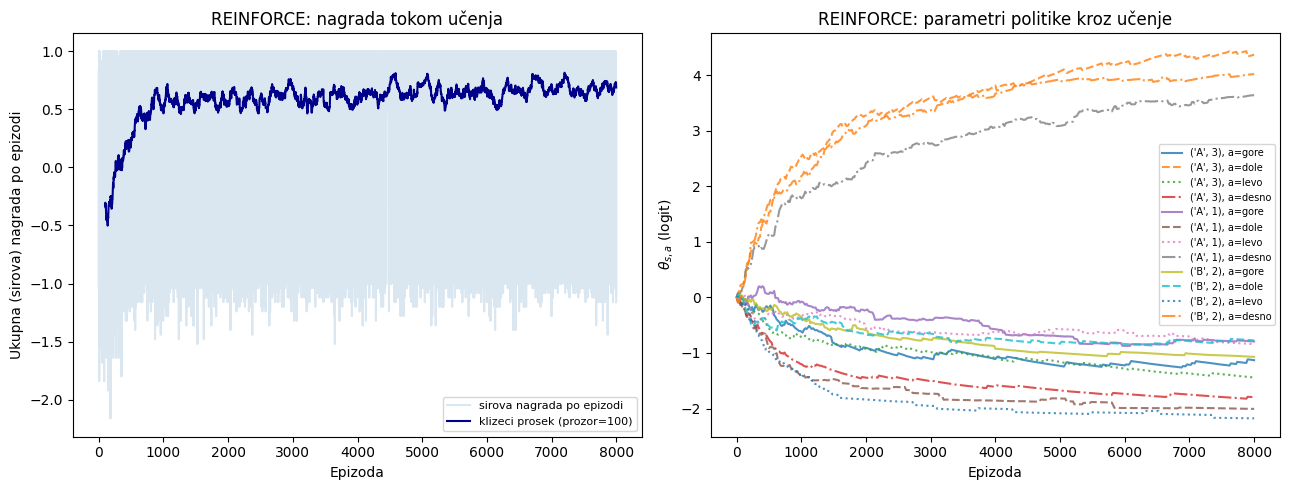

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# nagrada po epizodi, sirova vrednost je suvise zasumljena,
ax = axes[0]
window = 100
raw = np.array(rewards_rf)
if len(raw) >= window:
    moving_avg = np.convolve(raw, np.ones(window)/window, mode='valid')
    ax.plot(raw, alpha=0.2, color='steelblue', label='sirova nagrada po epizodi')
    ax.plot(np.arange(window-1, len(raw)), moving_avg, color='darkblue',
            label=f'klizeci prosek (prozor={window})')
else:
    ax.plot(raw, color='steelblue')
ax.set_xlabel("Epizoda")
ax.set_ylabel("Ukupna (sirova) nagrada po epizodi")
ax.set_title("REINFORCE: nagrada tokom učenja")
ax.legend(fontsize=8)

#  parametri politike (logiti) za par stanja
ax2 = axes[1]
states_to_plot = [('A', 3), ('A', 1), ('B', 2)]
state_idx = policy_rf.state_idx
linestyles = ['-', '--', ':', '-.']
for s in states_to_plot:
    si = state_idx[s]
    eps_list = [h[0] for h in theta_hist]
    for ai, a in enumerate(ACTIONS):
        vals = [h[1][si, ai] for h in theta_hist]
        ax2.plot(eps_list, vals, linestyle=linestyles[ai],
                  label=f"{s}, a={a}", alpha=0.8)
ax2.set_xlabel("Epizoda")
ax2.set_ylabel(r"$\theta_{s,a}$ (logit)")
ax2.set_title("REINFORCE: parametri politike kroz učenje")
ax2.legend(fontsize=7, ncol=1)

plt.tight_layout()
plt.show()